# Lab 6: k-Nearest Neighbours for Movie Genres

MLPR, Semester 4. Classifies movies as Action or Drama from their duration and rating with k-NN. Tries odd values of k from 1 to 499 and evaluates the best one with a confusion matrix, precision, recall and F1.

train (2797, 4) test (699, 4)


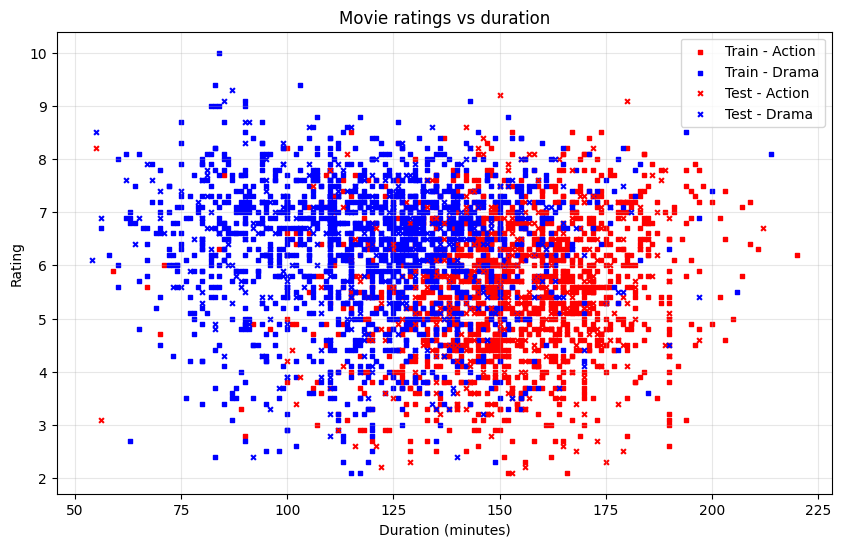

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score

train_data = pd.read_csv("data/tblTrain.csv")
test_data = pd.read_csv("data/tblTest.csv")
print("train", train_data.shape, "test", test_data.shape)

color_map = {"Action": "red", "Drama": "blue"}
plt.figure(figsize=(10, 6))
for df, marker, name in [(train_data, "s", "Train"), (test_data, "x", "Test")]:
    for genre, colour in color_map.items():
        d = df[df["Genre"] == genre]
        plt.scatter(d["Duration"], d["Rating"], c=colour, marker=marker, s=12, label=f"{name} - {genre}")
plt.xlabel("Duration (minutes)"); plt.ylabel("Rating"); plt.title("Movie ratings vs duration")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

Best k: 69, best accuracy: 0.8026


Precision: 0.804, Recall: 0.789, F1: 0.796


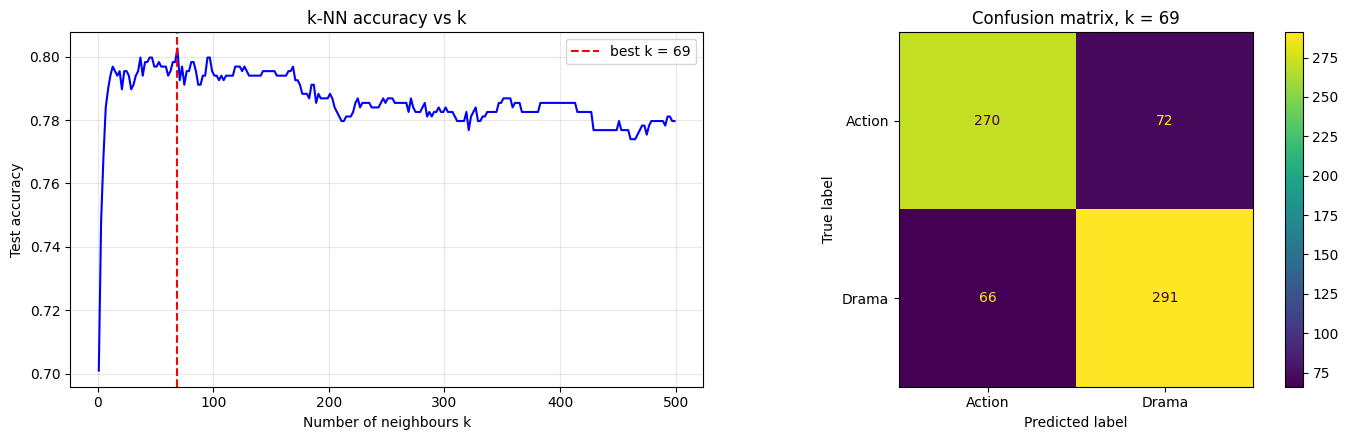

In [2]:
X_train, y_train = train_data[["Duration", "Rating"]].values, train_data["Genre"].values
X_test, y_test = test_data[["Duration", "Rating"]].values, test_data["Genre"].values

knn_neighbors = list(range(1, 500, 2))
accuracies = [KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train).score(X_test, y_test) for k in knn_neighbors]
best_k = knn_neighbors[int(np.argmax(accuracies))]
print(f"Best k: {best_k}, best accuracy: {max(accuracies):.4f}")

y_pred_best = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train).predict(X_test)
print(f"Precision: {precision_score(y_test, y_pred_best, pos_label='Action'):.3f}, "
      f"Recall: {recall_score(y_test, y_pred_best, pos_label='Action'):.3f}, "
      f"F1: {f1_score(y_test, y_pred_best, pos_label='Action'):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(knn_neighbors, accuracies, color="b")
axes[0].axvline(best_k, color="r", ls="--", label=f"best k = {best_k}")
axes[0].set_xlabel("Number of neighbours k"); axes[0].set_ylabel("Test accuracy"); axes[0].set_title("k-NN accuracy vs k")
axes[0].legend(); axes[0].grid(alpha=0.3)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_best, labels=["Action", "Drama"]), display_labels=["Action", "Drama"]).plot(ax=axes[1])
axes[1].set_title(f"Confusion matrix, k = {best_k}")
plt.tight_layout()
plt.savefig("images/lab06_knn.png")
plt.show()

## Report

1. **What k determines:** the number of nearest neighbours that vote on the class of a new point. It controls how smooth the decision boundary is.
2. **Choosing k:** plot accuracy against k and pick the best value, or (more reliably) use cross-validation on the training data so the test set stays untouched.
3. **k and bias/variance:** a small k overfits (low bias, high variance). A large k underfits (high bias, low variance). The best k balances both.
4. **Sensitivity to outliers:** yes. Predictions depend directly on the nearest points, so noisy or outlying points can flip the vote, especially for small k. In high dimensions, distances between all points also become similar.
5. **Feature scale:** k-NN uses distances, so a feature with a larger range (here duration in minutes vs a rating out of 10) dominates. Scaling the features usually improves accuracy.